In [2]:
import os
os.makedirs("results", exist_ok=True)

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    "processed/galaxies_processed.csv.gz",
    dtype={"specObjID": "string"},
)


df.shape

(494502, 7)

In [4]:
OMEGA_M = 0.332

z_grid = np.linspace(0, df["z"].max(), 10000)

inverse_E = 1 / np.sqrt(
    OMEGA_M * (1 + z_grid)**3 + 1 - OMEGA_M
)

area = (
    (inverse_E[:-1] + inverse_E[1:])
    / 2
    * np.diff(z_grid)
)

integral = np.r_[0, np.cumsum(area)]

distance = 2997.92458 * np.interp(
    df["z"], z_grid, integral
)

ra = np.deg2rad(df["ra"].to_numpy())
dec = np.deg2rad(df["dec"].to_numpy())

coordinates = df[["specObjID", "ra", "dec", "z"]].copy()

coordinates["distance"] = distance
coordinates["X"] = distance * np.cos(dec) * np.cos(ra)
coordinates["Y"] = distance * np.cos(dec) * np.sin(ra)
coordinates["Z"] = distance * np.sin(dec)

coordinates.to_csv(
    "results/galaxy_coordinates.csv.gz",
    index=False,
    compression="gzip",
)

pd.Series({
    "omega_m": OMEGA_M,
    "model": "flat LCDM",
    "distance_unit": "h^-1 Mpc",
    "rows": len(coordinates),
}).to_json(
    "results/coordinate_settings.json",
    indent=2,
)

coordinates.head()

,specObjID,ra,dec,z,distance,X,Y,Z
0,495401488193972224,124.86550,48.453868,0.180736,516.914797,-195.979263,281.290487,386.870389
1,495402862583506944,125.01663,48.847020,0.154864,446.013847,-168.419692,240.379722,335.828451
2,495406435996297216,124.87658,49.039169,0.140260,405.533492,-152.012765,218.095115,306.241822
3,495561192257906688,125.06450,49.859703,0.094595,276.818632,-102.521679,146.065886,211.619039
4,495561467135813632,125.05615,49.844886,0.138068,399.427201,-147.945237,210.847609,305.282790


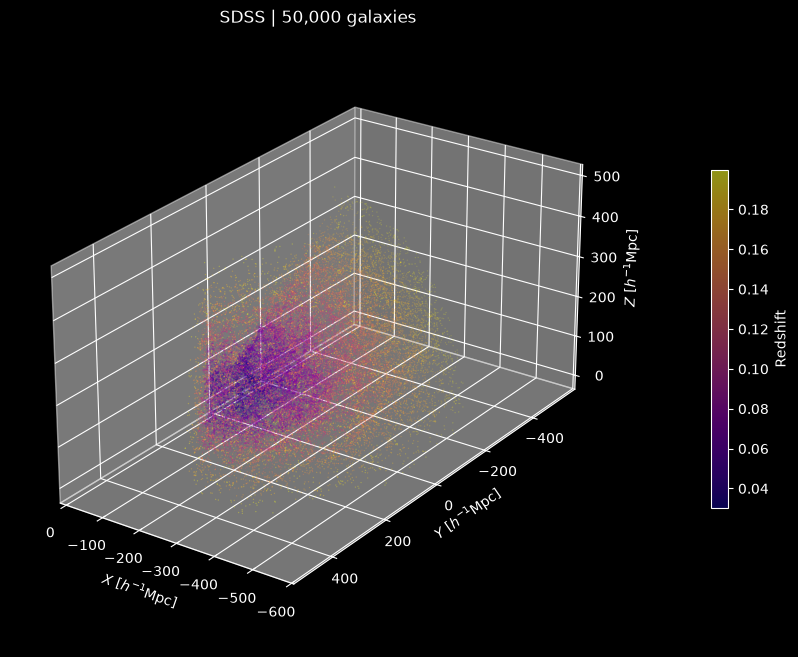

In [5]:
coordinates = pd.read_csv(
    "results/galaxy_coordinates.csv.gz",
    dtype={"specObjID": "string"},
)

sample = coordinates.sample(
    n=min(50000, len(coordinates)),
    random_state=42,
)

with plt.style.context("dark_background"):
    fig = plt.figure(figsize=(11, 8))
    ax = fig.add_subplot(111, projection="3d")

    points = ax.scatter(
        sample["X"],
        sample["Y"],
        sample["Z"],
        c=sample["z"],
        cmap="plasma",
        s=1,
        alpha=0.6,
        linewidths=0,
    )

    span = np.ptp(sample[["X", "Y", "Z"]].to_numpy(), axis=0)
    ax.set_box_aspect(np.maximum(span, 1))

    ax.set_xlabel(r"$X\ [h^{-1}\mathrm{Mpc}]$")
    ax.set_ylabel(r"$Y\ [h^{-1}\mathrm{Mpc}]$")
    ax.set_zlabel(r"$Z\ [h^{-1}\mathrm{Mpc}]$")
    ax.set_title(f"SDSS | {len(sample):,} galaxies")
    ax.view_init(elev=25, azim=125)

    fig.colorbar(
        points,
        ax=ax,
        label="Redshift",
        shrink=0.55,
        pad=0.1,
    )

    fig.savefig(
        "results/galaxies_3d.png",
        dpi=200,
        bbox_inches="tight",
    )
    plt.show()